
1. DATASET SIZE
Rows    : 2800
Columns : 10

2. FIRST 5 ROWS


,employee_id,department,role_level,monthly_salary,avg_weekly_hours,projects_handled,performance_rating,absences_days,job_satisfaction,attrition
0,1,HR,Junior,81750,55,1,1,17,1,Yes
1,2,Engineering,Senior,58140,36,2,4,13,1,Yes
2,3,Finance,Mid,37747,61,2,2,20,5,No
3,4,Finance,Senior,81993,36,4,1,17,2,Yes
4,5,Sales,Senior,45439,53,5,5,5,1,No



3. COLUMN INFORMATION


,Column,Data Type,Missing Values,Unique Values
employee_id,employee_id,int64,0,2800
department,department,str,0,6
role_level,role_level,str,0,3
monthly_salary,monthly_salary,int64,0,2753
avg_weekly_hours,avg_weekly_hours,int64,0,31
projects_handled,projects_handled,int64,0,8
performance_rating,performance_rating,int64,0,5
absences_days,absences_days,int64,0,21
job_satisfaction,job_satisfaction,int64,0,5
attrition,attrition,str,0,2



4. DUPLICATES
Duplicate rows: 0

5. MISSING VALUES
No missing values found.

6. NUMERICAL COLUMNS
['employee_id', 'monthly_salary', 'avg_weekly_hours', 'projects_handled', 'performance_rating', 'absences_days', 'job_satisfaction']

7. CATEGORICAL COLUMNS
['department', 'role_level', 'attrition']

8. NUMERICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
employee_id,2800.0,1400.500000,808.434702,1.0,700.75,1400.5,2100.25,2800.0
monthly_salary,2800.0,74492.075000,25899.209391,30006.0,51665.00,74587.5,97249.50,119977.0
avg_weekly_hours,2800.0,49.842500,8.980976,35.0,42.00,50.0,57.00,65.0
projects_handled,2800.0,4.519286,2.286778,1.0,3.00,4.0,7.00,8.0
performance_rating,2800.0,2.960714,1.404794,1.0,2.00,3.0,4.00,5.0
absences_days,2800.0,9.995000,6.056656,0.0,5.00,10.0,15.00,20.0
job_satisfaction,2800.0,2.995357,1.414332,1.0,2.00,3.0,4.00,5.0



9. ATTRITION DISTRIBUTION

Count:
attrition
No     1660
Yes    1140
Name: count, dtype: int64

Percentage:
attrition
No     59.29
Yes    40.71
Name: proportion, dtype: float64

10. CATEGORICAL VALUE COUNTS

 department
department
Marketing      494
HR             478
Engineering    469
Operations     464
Finance        461
Sales          434
Name: count, dtype: int64

 role_level
role_level
Senior    953
Mid       932
Junior    915
Name: count, dtype: int64

 attrition
attrition
No     1660
Yes    1140
Name: count, dtype: int64

11. TARGET ENCODING
Unique target values: <ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str

12. NUMERICAL FEATURES BY ATTRITION

 monthly_salary
attrition
No     74677.40
Yes    74222.21
Name: monthly_salary, dtype: float64

 avg_weekly_hours
attrition
No     49.03
Yes    51.03
Name: avg_weekly_hours, dtype: float64

 projects_handled
attrition
No     4.50
Yes    4.55
Name: projects_handled, dtype: float64

 performance_rating
attrition
No     3.17
Yes  

,Correlation with Attrition
absences_days,0.162623
avg_weekly_hours,0.109173
projects_handled,0.012404
monthly_salary,-0.008636
employee_id,-0.019922
performance_rating,-0.178151
job_satisfaction,-0.246088



14. FEATURES MOST RELATED TO ATTRITION
absences_days             : 0.163
avg_weekly_hours          : 0.109
projects_handled          : 0.012
monthly_salary            : -0.009
employee_id               : -0.020
performance_rating        : -0.178
job_satisfaction          : -0.246

15. VISUAL ANALYSIS


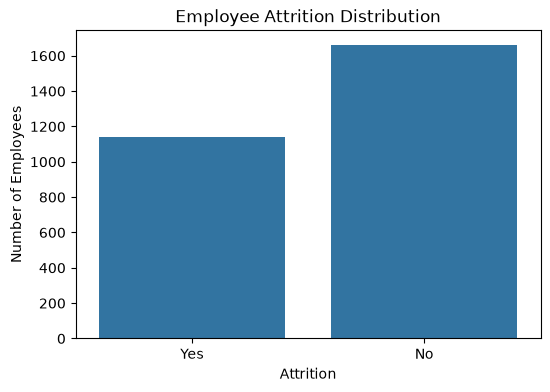

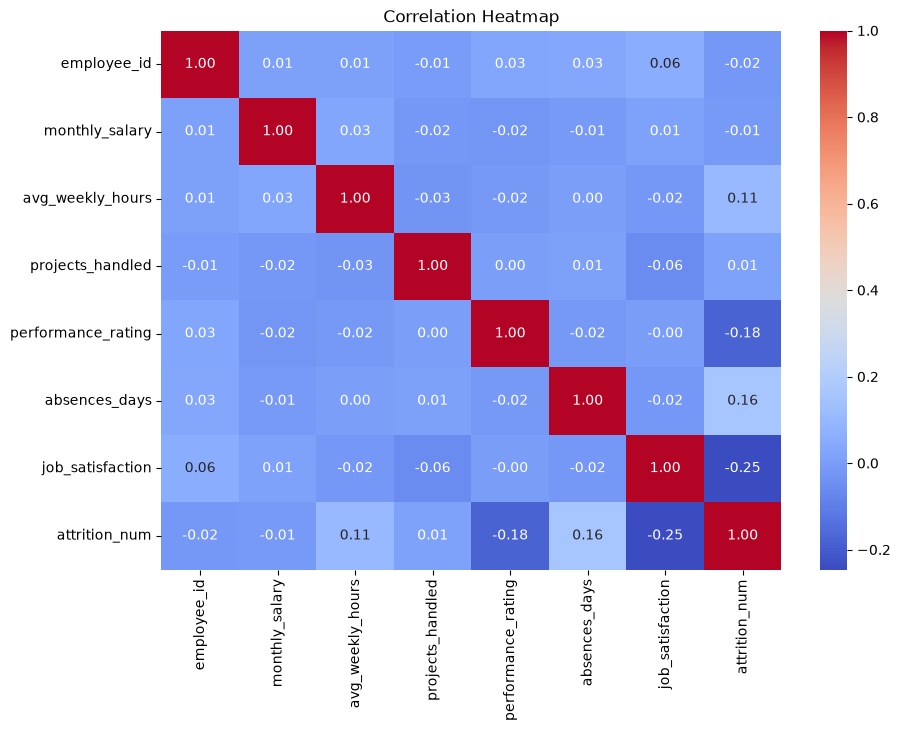

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("attrition.csv")

# 1. Dataset size
print("\n1. DATASET SIZE")
print("Rows    :", df.shape[0])
print("Columns :", df.shape[1])

# 2. First 5 rows
print("\n2. FIRST 5 ROWS")
display(df.head())

# 3. Column information
print("\n3. COLUMN INFORMATION")
info = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str),
    "Missing Values": df.isnull().sum(),
    "Unique Values": df.nunique()
})
display(info)

# 4. Duplicate rows
print("\n4. DUPLICATES")
print("Duplicate rows:", df.duplicated().sum())

# 5. Missing values
print("\n5. MISSING VALUES")
missing = df.isnull().sum()
missing = missing[missing > 0]

if len(missing) == 0:
    print("No missing values found.")
else:
    print(missing)

# 6. Numerical columns
num_cols = df.select_dtypes(include=np.number).columns.tolist()

print("\n6. NUMERICAL COLUMNS")
print(num_cols)

# 7. Categorical columns
cat_cols = df.select_dtypes(include=["object", "string", "category"]).columns.tolist()

print("\n7. CATEGORICAL COLUMNS")
print(cat_cols)

# 8. Numerical summary
print("\n8. NUMERICAL SUMMARY")
display(df[num_cols].describe().T)

# 9. Target distribution
print("\n9. ATTRITION DISTRIBUTION")

print("\nCount:")
print(df["attrition"].value_counts())

print("\nPercentage:")
print((df["attrition"].value_counts(normalize=True) * 100).round(2))

# 10. Unique values of categorical columns
print("\n10. CATEGORICAL VALUE COUNTS")

for col in cat_cols:
    print("\n", col)
    print(df[col].value_counts())

# 11. Check target encoding
print("\n11. TARGET ENCODING")

print("Unique target values:", df["attrition"].unique())

# 12. Numerical feature relationship with attrition
print("\n12. NUMERICAL FEATURES BY ATTRITION")

for col in num_cols:
    if col != "employee_id":
        print("\n", col)
        print(df.groupby("attrition")[col].mean().round(2))

# 13. Correlation
print("\n13. NUMERICAL CORRELATION WITH ATTRITION")

df_corr = df.copy()

# Convert target to 0/1
df_corr["attrition_num"] = df_corr["attrition"].map({
    "No": 0,
    "Yes": 1
})

corr = df_corr[num_cols + ["attrition_num"]].corr()["attrition_num"]
corr = corr.drop("attrition_num").sort_values(ascending=False)

display(corr.to_frame("Correlation with Attrition"))

# 14. Strongest numerical relationships
print("\n14. FEATURES MOST RELATED TO ATTRITION")

for feature, value in corr.items():
    print(f"{feature:25s} : {value:.3f}")

# 15. Basic visualizations
print("\n15. VISUAL ANALYSIS")

# Attrition count 
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="attrition")
plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.show()

# Correlation heatmap
plt.figure(figsize=(10,7))
sns.heatmap(
    df_corr[num_cols + ["attrition_num"]].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.show()



In [2]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from collections import Counter

# Remove employee ID because it does not help prediction
X = df.drop(columns=["attrition", "employee_id"], errors="ignore")

# Convert categorical features into numerical columns
X = pd.get_dummies(X, drop_first=True)

# Encode target
y = df["attrition"].map({"No": 0, "Yes": 1})

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))
print("Training features:", X_train.shape[1])

Training samples: 2240
Testing samples : 560
Training features: 13


In [3]:
np.random.seed(42)

n = len(X_train)
bootstrap_samples = []
oob_samples = []

for i in range(5):
    # Randomly select n row indices with replacement
    sample_indices = np.random.choice(
        n, size=n, replace=True
    )

    # Unique rows selected in the bootstrap sample
    unique_indices = np.unique(sample_indices)

    # Rows not selected: out-of-bag samples
    oob_indices = np.setdiff1d(
        np.arange(n), unique_indices
    )

    bootstrap_samples.append(sample_indices)
    oob_samples.append(oob_indices)

    unique_percentage = len(unique_indices) / n * 100
    oob_percentage = len(oob_indices) / n * 100

    print(f"\nBootstrap Sample {i + 1}")
    print("Total selections:", len(sample_indices))
    print("Unique samples  :", len(unique_indices))
    print("Unique percentage:", round(unique_percentage, 2), "%")
    print("OOB samples     :", len(oob_indices))
    print("OOB percentage  :", round(oob_percentage, 2), "%")


Bootstrap Sample 1
Total selections: 2240
Unique samples  : 1394
Unique percentage: 62.23 %
OOB samples     : 846
OOB percentage  : 37.77 %

Bootstrap Sample 2
Total selections: 2240
Unique samples  : 1397
Unique percentage: 62.37 %
OOB samples     : 843
OOB percentage  : 37.63 %

Bootstrap Sample 3
Total selections: 2240
Unique samples  : 1424
Unique percentage: 63.57 %
OOB samples     : 816
OOB percentage  : 36.43 %

Bootstrap Sample 4
Total selections: 2240
Unique samples  : 1413
Unique percentage: 63.08 %
OOB samples     : 827
OOB percentage  : 36.92 %

Bootstrap Sample 5
Total selections: 2240
Unique samples  : 1423
Unique percentage: 63.53 %
OOB samples     : 817
OOB percentage  : 36.47 %


In [4]:
trees = []
individual_accuracies = []

for i in range(5):
    sample_indices = bootstrap_samples[i]

    X_bootstrap = X_train.iloc[sample_indices]
    y_bootstrap = y_train.iloc[sample_indices]

    tree = DecisionTreeClassifier(random_state=42 + i)
    tree.fit(X_bootstrap, y_bootstrap)

    # Predict on the same common test set
    y_pred = tree.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    trees.append(tree)
    individual_accuracies.append(accuracy)

    print(f"Decision Tree {i + 1} Accuracy: {accuracy:.4f}")

Decision Tree 1 Accuracy: 0.5482
Decision Tree 2 Accuracy: 0.5500
Decision Tree 3 Accuracy: 0.5768
Decision Tree 4 Accuracy: 0.5732
Decision Tree 5 Accuracy: 0.5411


In [5]:
# Collect predictions from all five trees
tree_predictions = np.array([
    tree.predict(X_test) for tree in trees
])

# Majority voting for each test sample
bagged_predictions = []

for j in range(len(X_test)):
    votes = tree_predictions[:, j]
    majority_vote = Counter(votes).most_common(1)[0][0]
    bagged_predictions.append(majority_vote)

bagged_accuracy = accuracy_score(
    y_test, bagged_predictions
)

print("Bagged Ensemble Accuracy:", round(bagged_accuracy, 4))

Bagged Ensemble Accuracy: 0.5679


,Model,Accuracy,Accuracy (%)
0,Decision Tree 1,0.548214,54.82
1,Decision Tree 2,0.550000,55.00
2,Decision Tree 3,0.576786,57.68
3,Decision Tree 4,0.573214,57.32
4,Decision Tree 5,0.541071,54.11
5,Bagged Ensemble,0.567857,56.79


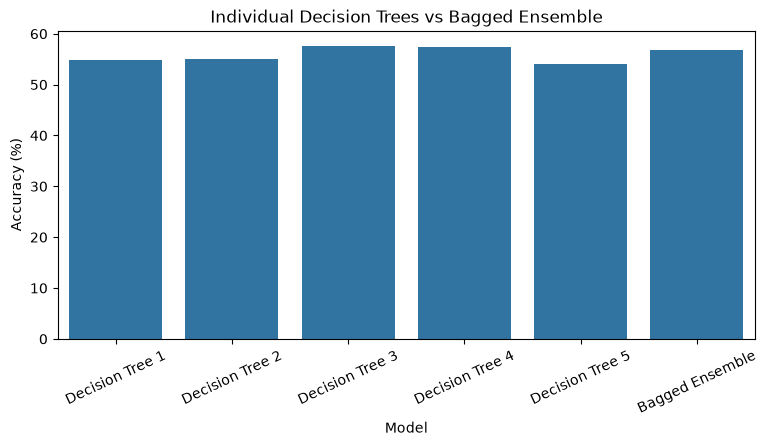

In [6]:
comparison = pd.DataFrame({
    "Model": [f"Decision Tree {i + 1}" for i in range(5)]
             + ["Bagged Ensemble"],
    "Accuracy": individual_accuracies + [bagged_accuracy]
})

comparison["Accuracy (%)"] = (
    comparison["Accuracy"] * 100
).round(2)

display(comparison)

plt.figure(figsize=(9, 4))
sns.barplot(data=comparison, x="Model", y="Accuracy (%)")
plt.title("Individual Decision Trees vs Bagged Ensemble")
plt.xlabel("Model")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=25)
plt.show()

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

results = []

max_features_options = ["sqrt", "log2", None]

for feature_option in max_features_options:
    model = RandomForestClassifier(
        n_estimators=100,
        max_features=feature_option,
        random_state=42
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    results.append({
        "Max Features": str(feature_option),
        "Accuracy": round(accuracy, 4)
    })

display(pd.DataFrame(results))

,Max Features,Accuracy
0,sqrt,0.6482
1,log2,0.6482
2,None,0.6179


In [8]:
tree_counts = [10, 25, 50, 100]
rf_accuracies = []

for n in tree_counts:
    model = RandomForestClassifier(
        n_estimators=n,
        max_depth=None,
        max_features="sqrt",
        random_state=42
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    rf_accuracies.append(accuracy)

    print(f"Trees: {n}, Accuracy: {accuracy:.4f}")

Trees: 10, Accuracy: 0.6196
Trees: 25, Accuracy: 0.6286
Trees: 50, Accuracy: 0.6339
Trees: 100, Accuracy: 0.6482


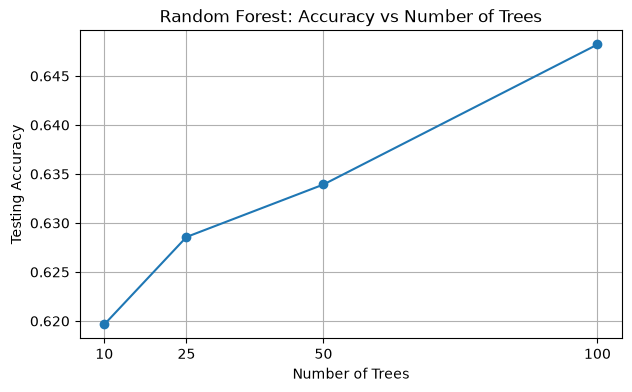

In [9]:
plt.figure(figsize=(7, 4))

plt.plot(
    tree_counts,
    rf_accuracies,
    marker="o"
)

plt.xlabel("Number of Trees")
plt.ylabel("Testing Accuracy")
plt.title("Random Forest: Accuracy vs Number of Trees")
plt.xticks(tree_counts)
plt.grid(True)
plt.show()

In [10]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [50, 100],
    "max_depth": [5, 10, None],
    "max_features": ["sqrt", "log2"]
}

rf = RandomForestClassifier(random_state=42)

grid = GridSearchCV(
    rf,
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV Accuracy:", round(grid.best_score_, 4))

best_rf = grid.best_estimator_
rf_predictions = best_rf.predict(X_test)

print("Test Accuracy:", round(
    accuracy_score(y_test, rf_predictions), 4
))

Best Parameters: {'max_depth': 5, 'max_features': 'sqrt', 'n_estimators': 100}
Best CV Accuracy: 0.6897
Test Accuracy: 0.6696


In [11]:
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_rf.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Top 10 Attrition Predictors:")
display(importance_df.head(10))

Top 10 Attrition Predictors:


,Feature,Importance
5,job_satisfaction,0.338368
3,performance_rating,0.171820
4,absences_days,0.163706
1,avg_weekly_hours,0.133466
0,monthly_salary,0.094224
2,projects_handled,0.035411
9,department_Operations,0.011673
10,department_Sales,0.010131
12,role_level_Senior,0.009705
7,department_HR,0.009352


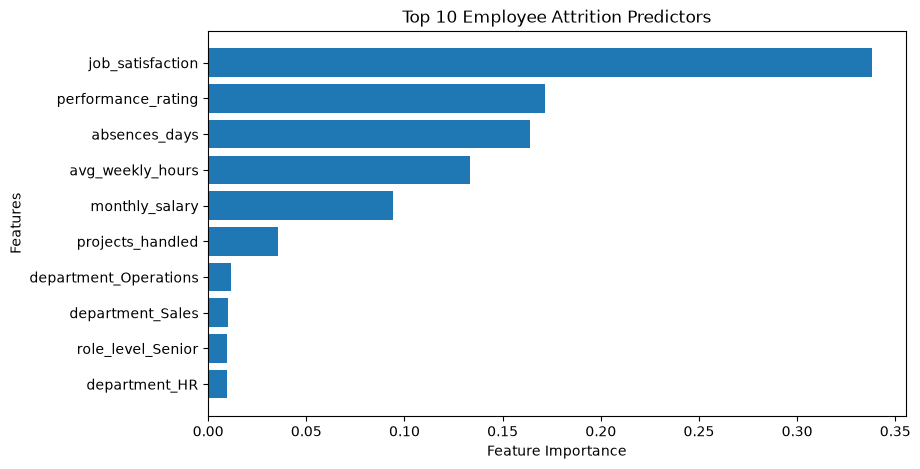

In [12]:
top10 = importance_df.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(9, 5))

plt.barh(
    top10["Feature"],
    top10["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Top 10 Employee Attrition Predictors")
plt.show()

In [13]:
print("Top 10 Features Affecting Attrition:")

for i, row in enumerate(
    importance_df.head(10).itertuples(index=False),
    start=1
):
    print(f"{i}. {row.Feature}: {row.Importance:.4f}")

Top 10 Features Affecting Attrition:
1. job_satisfaction: 0.3384
2. performance_rating: 0.1718
3. absences_days: 0.1637
4. avg_weekly_hours: 0.1335
5. monthly_salary: 0.0942
6. projects_handled: 0.0354
7. department_Operations: 0.0117
8. department_Sales: 0.0101
9. role_level_Senior: 0.0097
10. department_HR: 0.0094
